# 🌳 Decision Tree Regression — Car Price Prediction

**Course:** Big Data and Machine Learning · **Module 02:** Build and Evaluate Decision Tree Models

In this notebook we build, train, evaluate and visualize a **Decision Tree Regressor** that predicts the
manufacturer's suggested retail price (**MSRP**) of a car from its specifications.

### 🎯 Learning objectives
1. Understand how a regression tree differs from a classification tree.
2. Derive the **MSE / variance-reduction** split criterion and why a leaf predicts the **mean**.
3. Engineer a new feature (`Car_Age`) and build a scikit-learn `Pipeline`.
4. Evaluate regressors with **MAE, MSE, RMSE and $R^2$** — and compute them by hand.
5. Visualize the tree, its **piece-wise constant** predictions and its feature importances.
6. Diagnose **overfitting** and tune hyper-parameters with **cross-validation**.

### 📑 Contents
1. Concepts: regression trees
2. The mathematics of splitting (MSE / variance reduction)
3. Load & explore the data
4. Clean the data & engineer features
5. Build the pipeline and train the model
6. Evaluate the model (metrics + math)
7. Visualize the tree
8. Feature importance
9. Overfitting & the bias–variance trade-off
10. Hyper-parameter tuning with cross-validation
11. Summary & exercises

## 1. Concepts: regression trees

A **regression tree** has exactly the same structure as a classification tree (root, internal nodes, leaves), but:

| | Classification tree | Regression tree |
|---|---|---|
| Target | a class (e.g. *yes / no*) | a number (e.g. price in $) |
| Leaf prediction | majority class | **mean** of the target values in the leaf |
| Split criterion | Gini / Entropy | **MSE** (variance), MAE, Friedman MSE, Poisson |
| Metrics | accuracy, precision, recall, F1 | MAE, MSE, RMSE, $R^2$ |

Because every leaf outputs a constant, the model is a **step function** — it partitions the feature space into
regions $R_1, \dots, R_M$ and predicts
$$
\hat{f}(x) = \sum_{m=1}^{M} c_m \,\mathbb{1}(x \in R_m), \qquad c_m = \bar{y}_{R_m}
$$

## 2. The mathematics of splitting

### 2.1 Node impurity = mean squared error (variance)
For a node $t$ with $N_t$ samples and prediction $\bar{y}_t = \frac{1}{N_t}\sum_{i\in t} y_i$:
$$
\text{MSE}(t) = \frac{1}{N_t}\sum_{i \in t} \left(y_i - \bar{y}_t\right)^2
$$
This is just the **variance** of the target inside the node.

### 2.2 Why does a leaf predict the mean?
We want the constant $c$ that minimizes the squared error $\sum_i (y_i - c)^2$. Setting the derivative to zero:
$$
\frac{d}{dc}\sum_{i}(y_i - c)^2 = -2\sum_i (y_i - c) = 0 \;\;\Longrightarrow\;\; c = \frac{1}{N}\sum_i y_i = \bar{y}
$$
(If we used the MAE criterion instead, the optimal constant would be the **median**.)

### 2.3 Variance reduction
For a split of parent $P$ into $L$ and $R$:
$$
\Delta = \text{MSE}(P) - \left(\frac{N_L}{N_P}\,\text{MSE}(L) + \frac{N_R}{N_P}\,\text{MSE}(R)\right)
$$
The tree greedily chooses $(j^*, t^*) = \arg\max_{j,t} \Delta(j,t)$.

### 2.4 A tiny worked example
Prices (in \$1000s) in a node: $y = [10, 12, 30, 34]$, so $\bar y = 21.5$.
$$
\text{MSE}(P) = \tfrac{1}{4}\left[(11.5)^2 + (9.5)^2 + (8.5)^2 + (12.5)^2\right] = \tfrac{1}{4}(132.25+90.25+72.25+156.25) = 112.75
$$
Split into $L=[10,12]$ ($\bar y_L = 11$, MSE $=1$) and $R=[30,34]$ ($\bar y_R = 32$, MSE $=4$):
$$
\Delta = 112.75 - \left(\tfrac{2}{4}\cdot 1 + \tfrac{2}{4}\cdot 4\right) = 112.75 - 2.5 = 110.25
$$
Almost all the variance is explained by this one split.

In [1]:
# Importing the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

In [2]:
# MSE impurity and variance reduction, written from the formulas above
def mse(y):
    y = np.asarray(y, dtype=float)
    return np.mean((y - y.mean()) ** 2)

def variance_reduction(parent, left, right):
    n_p, n_l, n_r = len(parent), len(left), len(right)
    return mse(parent) - (n_l / n_p * mse(left) + n_r / n_p * mse(right))

parent, left, right = [10, 12, 30, 34], [10, 12], [30, 34]
print(f"MSE(parent) = {mse(parent):.2f}   MSE(left) = {mse(left):.2f}   MSE(right) = {mse(right):.2f}")
print(f"Variance reduction = {variance_reduction(parent, left, right):.2f}")

MSE(parent) = 112.75   MSE(left) = 1.00   MSE(right) = 4.00
Variance reduction = 110.25


## 3. Load & explore the dataset

Each row describes a car model (make, engine, transmission, size, fuel economy, …) and its **MSRP** in US dollars.

> 💡 The CSV is loaded with a **relative path**, so the notebook runs as-is after you clone/fork the repository.
> On Google Colab the file is downloaded automatically from the GitHub repository.

In [3]:
# -------------------------------
# Load the Data
# -------------------------------
import os
# Use the local file if present (cloned/forked repo), otherwise download it from GitHub (e.g. on Colab)
DATA_PATH = "content/Car Price Prediction.csv" if os.path.exists("content/Car Price Prediction.csv") else "https://raw.githubusercontent.com/ab3lT/decision-trees-big-data-ml/main/content/Car%20Price%20Prediction.csv"
data = pd.read_csv(DATA_PATH)

print(f"Shape: {data.shape[0]} rows x {data.shape[1]} columns\n")
# Print dataset schema (column names and data types)
print("Dataset Schema:")
print(data.dtypes)

Shape: 11914 rows x 16 columns

Dataset Schema:
Make                     str
Model                    str
Year                   int64
Engine Fuel Type         str
Engine HP            float64
Engine Cylinders     float64
Transmission Type        str
Driven_Wheels            str
Number of Doors      float64
Market Category          str
Vehicle Size             str
Vehicle Style            str
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object


In [4]:
# Show the first 5 rows of the dataset
data.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [5]:
# -------------------------------
# Data Exploration
# -------------------------------

# Identify categorical columns (String or Boolean types)
categorical_cols = data.select_dtypes(include=['object', 'string', 'bool']).columns.tolist()

# Loop through each categorical column and get the count of distinct values
for col_name in categorical_cols:
    distinct_count = data[col_name].nunique()
    print(f"Column: {col_name:<18} - Distinct Count: {distinct_count}")

Column: Make               - Distinct Count: 48
Column: Model              - Distinct Count: 915
Column: Engine Fuel Type   - Distinct Count: 10
Column: Transmission Type  - Distinct Count: 5
Column: Driven_Wheels      - Distinct Count: 4
Column: Market Category    - Distinct Count: 71
Column: Vehicle Size       - Distinct Count: 3
Column: Vehicle Style      - Distinct Count: 16


In [6]:
# Data Summary
data.describe(include='all')

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
count,11914,11914,11914.000000,11911,11845.00000,11884.000000,11914,11914,11908.000000,8172,11914,11914,11914.000000,11914.000000,11914.000000,1.191400e+04
unique,48,915,NaN,10,NaN,NaN,5,4,NaN,71,3,16,NaN,NaN,NaN,NaN
top,Chevrolet,Silverado 1500,NaN,regular unleaded,NaN,NaN,AUTOMATIC,front wheel drive,NaN,Crossover,Compact,Sedan,NaN,NaN,NaN,NaN
freq,1123,156,NaN,7172,NaN,NaN,8266,4787,NaN,1110,4764,3048,NaN,NaN,NaN,NaN
mean,NaN,NaN,2010.384338,NaN,249.38607,5.628829,NaN,NaN,3.436093,NaN,NaN,NaN,26.637485,19.733255,1554.911197,4.059474e+04
std,NaN,NaN,7.579740,NaN,109.19187,1.780559,NaN,NaN,0.881315,NaN,NaN,NaN,8.863001,8.987798,1441.855347,6.010910e+04
min,NaN,NaN,1990.000000,NaN,55.00000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,12.000000,7.000000,2.000000,2.000000e+03
25%,NaN,NaN,2007.000000,NaN,170.00000,4.000000,NaN,NaN,2.000000,NaN,NaN,NaN,22.000000,16.000000,549.000000,2.100000e+04
50%,NaN,NaN,2015.000000,NaN,227.00000,6.000000,NaN,NaN,4.000000,NaN,NaN,NaN,26.000000,18.000000,1385.000000,2.999500e+04
75%,NaN,NaN,2016.000000,NaN,300.00000,6.000000,NaN,NaN,4.000000,NaN,NaN,NaN,30.000000,22.000000,2009.000000,4.223125e+04


### The target: MSRP
Car prices are **right-skewed** — a few super-cars cost far more than typical cars. Squared-error criteria are sensitive
to such extreme values, which is worth keeping in mind when we read RMSE later.

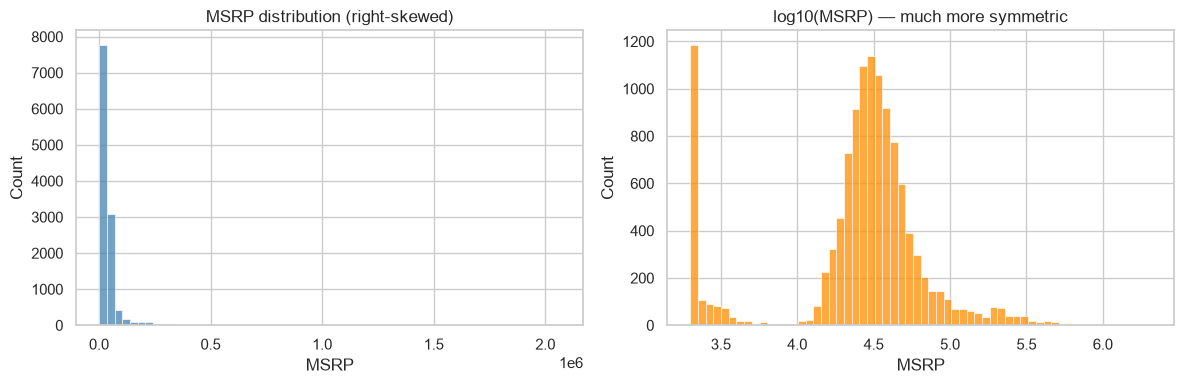

count      11914.0
mean       40595.0
std        60109.0
min         2000.0
25%        21000.0
50%        29995.0
75%        42231.0
max      2065902.0
Name: MSRP, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data['MSRP'], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("MSRP distribution (right-skewed)")
sns.histplot(np.log10(data['MSRP']), bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("log10(MSRP) — much more symmetric")
plt.tight_layout(); plt.show()

print(data['MSRP'].describe().round(0))

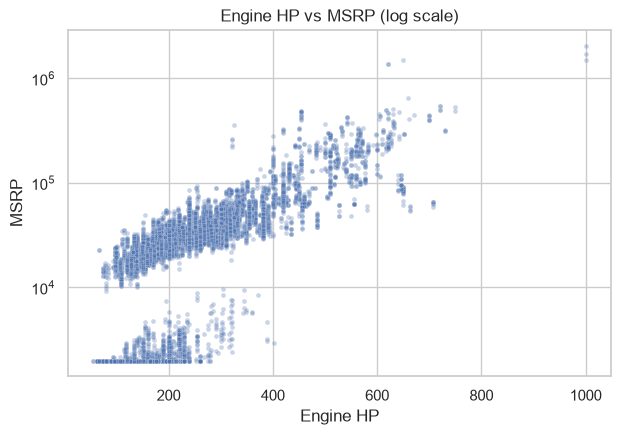

In [8]:
# Relationship between engine power and price
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x='Engine HP', y='MSRP', data=data, alpha=0.3, s=12)
plt.yscale('log')
plt.title("Engine HP vs MSRP (log scale)")
plt.show()

## 4. Clean the data & engineer features

In [9]:
# Function to check for null values in the columns
def check_nulls_in_columns(data, columns):
    '''
    Identifies the number of null occurrences in each column.

    :param data: Pandas DataFrame
    :param columns: List of column names
    '''
    for col in columns:
        na_count = data[col].isna().sum()
        if na_count > 0:
            print(f"Column: {col:<18} - Null Occurrences: {na_count} ({na_count / len(data):.1%})")

# Identify null occurrences in all columns of our dataset
check_nulls_in_columns(data, data.columns)

Column: Engine Fuel Type   - Null Occurrences: 3 (0.0%)
Column: Engine HP          - Null Occurrences: 69 (0.6%)
Column: Engine Cylinders   - Null Occurrences: 30 (0.3%)
Column: Number of Doors    - Null Occurrences: 6 (0.1%)
Column: Market Category    - Null Occurrences: 3742 (31.4%)


**Cleaning decisions**
* `Market Category` has thousands of nulls (≈ 30 %) and is a free-text combination of tags ➜ **drop the column**.
* The remaining nulls are few ➜ **drop those rows**.

In [10]:
# Dropping the 'Market Category' column since it has too many null values
data = data.drop(columns=['Market Category'])

# Drop rows with nulls
data = data.dropna()
print(f"Data after cleaning: Rows - {data.shape[0]}, Columns - {data.shape[1]}")

Data after cleaning: Rows - 11812, Columns - 15


### Feature extraction: `Car_Age`
The model year is more meaningful as an **age**:
$$
\text{Car\_Age} = \text{current year} - \text{Year}
$$
> Note: for a tree this is a monotone transformation of `Year`, so the splits are equivalent — but `Car_Age` is easier to interpret.

In [11]:
from datetime import datetime

# Get the current year dynamically
current_year = datetime.now().year

# Create 'Car_Age' feature and drop 'Year' column
data['Car_Age'] = current_year - data['Year']
data = data.drop(columns=['Year'])
data[['Make', 'Model', 'Car_Age', 'MSRP']].head()

,Make,Model,Car_Age,MSRP
0,BMW,1 Series M,15,46135
1,BMW,1 Series,15,40650
2,BMW,1 Series,15,36350
3,BMW,1 Series,15,29450
4,BMW,1 Series,15,34500


### Feature selection & encoding

| Step | Why |
|------|-----|
| **One-hot encoding** of categorical columns | Converts e.g. `Transmission Type` into binary columns. `drop='first'` removes one redundant column per feature. `Make`/`Model` are **not** used (Model has ~900 values ➜ very high cardinality). |
| **Standard scaling** $z = \dfrac{x-\mu}{\sigma}$ | ⚠️ Not required by trees (splits are invariant to monotone transformations); kept so the pipeline can be reused with other models. |

In [12]:
# Update the list of categorical and numerical feature columns
categorical_cols = ["Engine Fuel Type", "Transmission Type", "Driven_Wheels", "Vehicle Size", "Vehicle Style"]
numeric_cols = ["Engine HP", "Engine Cylinders", "highway MPG", "city mpg", "Popularity", "Car_Age"]

# Encode categorical features & standardize numerical features
categorical_encoder = OneHotEncoder(handle_unknown='ignore', drop='first')
numeric_scaler = StandardScaler()

# Passing the predefined list of categorical and numerical columns through the Column Transformer.
# Any additional column (Make, Model, Number of Doors) will be dropped.
preprocessor = ColumnTransformer([
    ('num', numeric_scaler, numeric_cols),
    ('cat', categorical_encoder, categorical_cols)
])

## 5. Build the pipeline and train the model

* 80 / 20 train–test split.
* `DecisionTreeRegressor(criterion='squared_error', max_depth=5)` — the MSE criterion from Section 2, with
  **pre-pruning** at depth 5.

In [13]:
# Split data into features (X) and target (y)
X = data.drop(columns=['MSRP'])
y = data['MSRP']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Create a pipeline with preprocessor and Decision Tree Regressor
dt_regressor = DecisionTreeRegressor(criterion='squared_error', max_depth=5, random_state=RANDOM_STATE)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', dt_regressor)
])

# Train the model
pipeline.fit(X_train, y_train)

# Make predictions
y_pred = pipeline.predict(X_test)

# Show some predictions
df = pd.DataFrame({'Actual MSRP': y_test, 'Predicted MSRP': y_pred.astype(int)})
print(df.head(10).to_string(index=False))

Train: (9449, 14), Test: (2363, 14)
 Actual MSRP  Predicted MSRP
        2000            2101
       20500           19963
       20585           19963
      116700           96970
       40675           37798
       17930           19963
       45550           37798
        2713            2972
       37600           37798
       48450           37798


### 🔎 Check the math: the root node
The root node's **value** must equal the mean training price, and its **impurity** must equal the variance of `y_train`.

In [14]:
tree = pipeline.named_steps['regressor'].tree_
print(f"Mean of y_train        : {y_train.mean():,.2f}")
print(f"Root node value        : {tree.value[0][0][0]:,.2f}")
print(f"MSE (variance) by hand : {mse(y_train):,.2f}")
print(f"Root impurity (sklearn): {tree.impurity[0]:,.2f}")

# Leaves predict the mean of their training samples - check one leaf
leaf_ids = pipeline.named_steps['regressor'].apply(pipeline.named_steps['preprocessor'].transform(X_train))
some_leaf = pd.Series(leaf_ids).value_counts().index[0]
print(f"\nLeaf {some_leaf}: mean of its training targets = {y_train[leaf_ids == some_leaf].mean():,.2f}, "
      f"leaf value = {tree.value[some_leaf][0][0]:,.2f}")

Mean of y_train        : 40,726.67
Root node value        : 40,726.67
MSE (variance) by hand : 3,986,483,024.28
Root impurity (sklearn): 3,986,483,024.28

Leaf 8: mean of its training targets = 37,798.14, leaf value = 37,798.14


## 6. Evaluate the model

With $y_i$ the true price, $\hat y_i$ the prediction and $n$ test samples:
$$
\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}\lvert y_i - \hat y_i\rvert
\qquad
\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2
\qquad
\text{RMSE} = \sqrt{\text{MSE}}
$$
$$
R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2} = 1 - \frac{SS_{res}}{SS_{tot}}
$$

* **MAE / RMSE** are in dollars. RMSE punishes large errors more (because of the square).
* **$R^2$** is the share of the target's variance the model explains: $1$ = perfect, $0$ = no better than always predicting the mean $\bar y$.

In [15]:
# Evaluate the model using scikit-learn
mae = mean_absolute_error(y_test, y_pred)
mse_test = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse_test)
r2 = r2_score(y_test, y_pred)

print("Evaluation Metrics")
print(f"Mean Absolute Error (MAE)     : {mae:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R-squared (R2)                : {r2:.3f}")

Evaluation Metrics
Mean Absolute Error (MAE)     : 8,044.44
Root Mean Squared Error (RMSE): 17,411.19
R-squared (R2)                : 0.864


In [16]:
# Re-compute the metrics directly from the formulas
err = y_test.to_numpy() - y_pred
ss_res = np.sum(err ** 2)
ss_tot = np.sum((y_test - y_test.mean()) ** 2)
print(f"MAE  by hand = {np.mean(np.abs(err)):,.2f}")
print(f"RMSE by hand = {np.sqrt(np.mean(err ** 2)):,.2f}")
print(f"R2   by hand = 1 - {ss_res:.3e} / {ss_tot:.3e} = {1 - ss_res / ss_tot:.3f}")

MAE  by hand = 8,044.44
RMSE by hand = 17,411.19
R2   by hand = 1 - 7.163e+11 / 5.254e+12 = 0.864


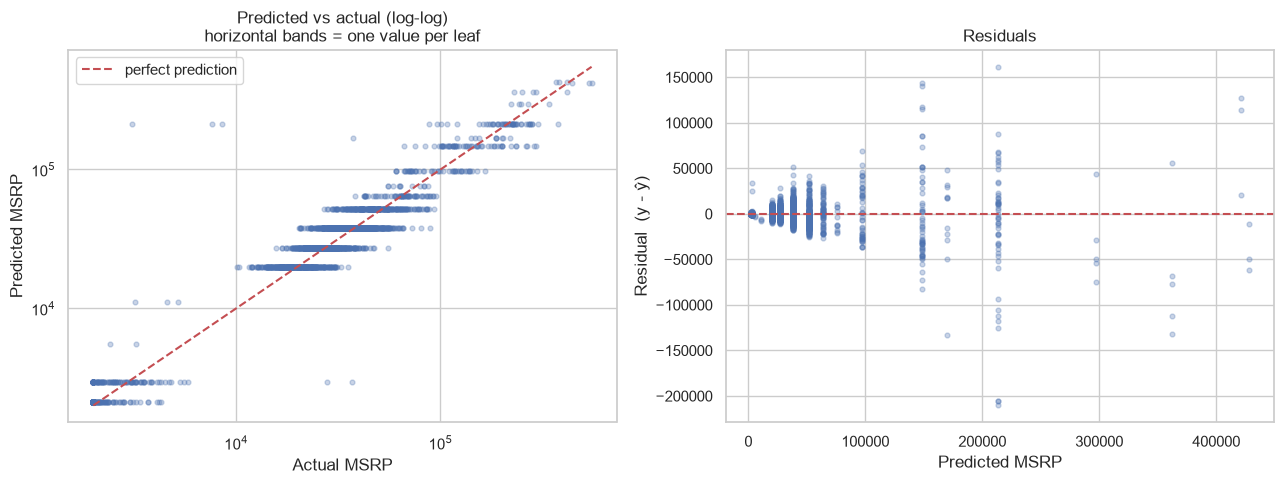

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=12)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel("Actual MSRP"); axes[0].set_ylabel("Predicted MSRP")
axes[0].set_title("Predicted vs actual (log-log)\nhorizontal bands = one value per leaf")
axes[0].legend()

axes[1].scatter(y_pred, err, alpha=0.3, s=12)
axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted MSRP"); axes[1].set_ylabel("Residual  (y - ŷ)")
axes[1].set_title("Residuals")
plt.tight_layout(); plt.show()

## 7. Visualize the decision tree

Each box shows the **split rule** (in scaled units), the node's **squared_error** (variance), the number of
**samples**, and **value** = the mean MSRP of those samples (= the prediction if this node were a leaf).
We show only the top 3 levels so it stays readable.

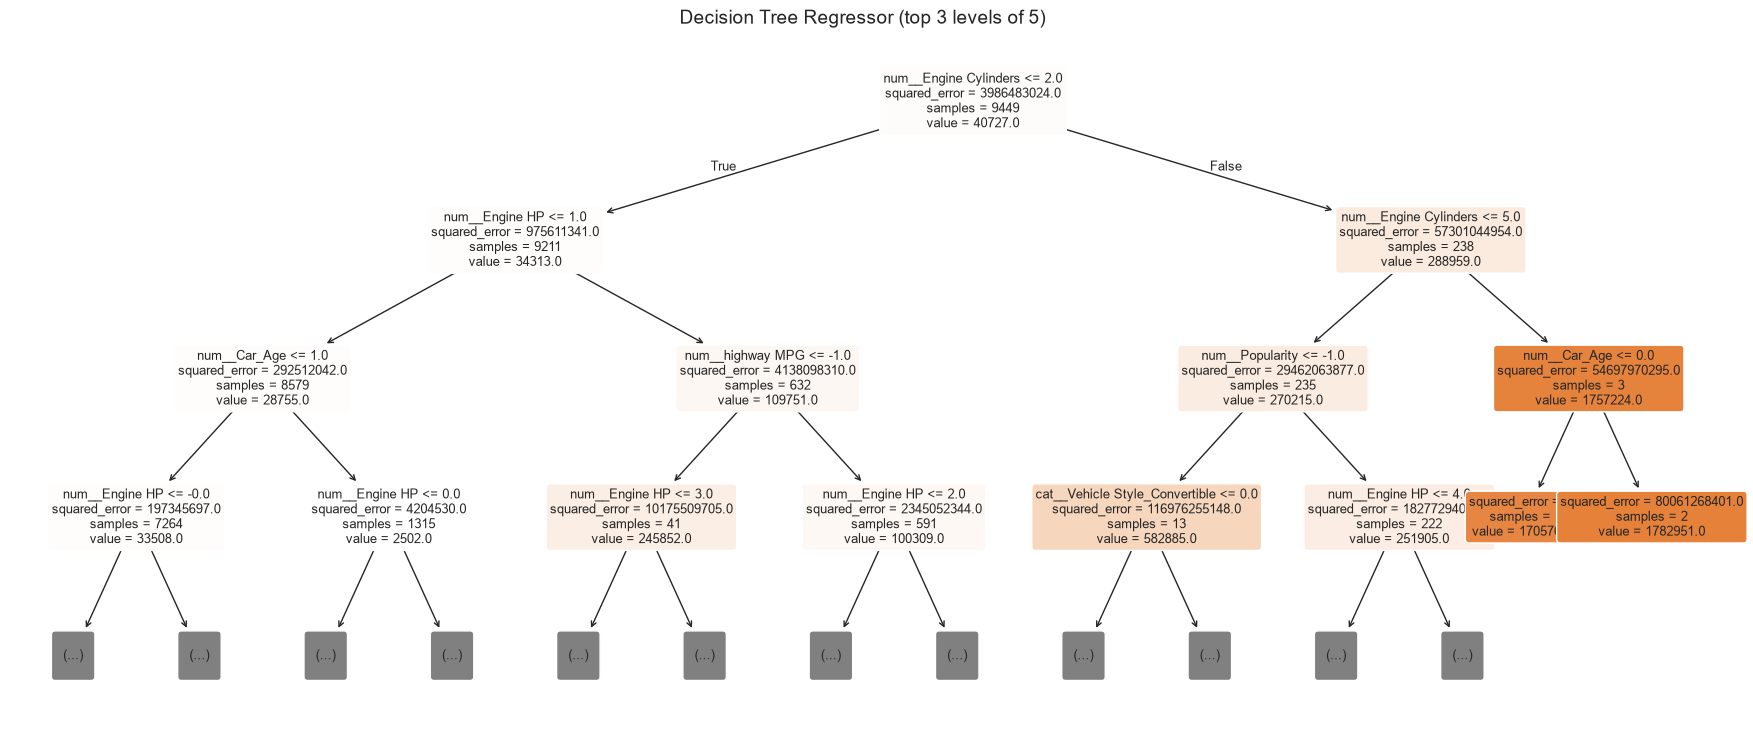

In [18]:
# Get transformed feature names and the trained Decision Tree from the pipeline
transformed_feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
dt_model = pipeline.named_steps['regressor']

plt.figure(figsize=(22, 9))
plot_tree(dt_model, feature_names=transformed_feature_names,
          filled=True, rounded=True, max_depth=3, fontsize=9, precision=0)
plt.title("Decision Tree Regressor (top 3 levels of 5)", fontsize=14)
plt.show()

In [19]:
# The full tree as text rules
print(export_text(dt_model, feature_names=list(transformed_feature_names), decimals=2))

|--- num__Engine Cylinders <= 1.93
|   |--- num__Engine HP <= 1.32
|   |   |--- num__Car_Age <= 1.29
|   |   |   |--- num__Engine HP <= -0.30
|   |   |   |   |--- num__Engine HP <= -0.76
|   |   |   |   |   |--- value: [19963.99]
|   |   |   |   |--- num__Engine HP >  -0.76
|   |   |   |   |   |--- value: [27158.11]
|   |   |   |--- num__Engine HP >  -0.30
|   |   |   |   |--- num__Engine HP <= 0.57
|   |   |   |   |   |--- value: [37798.14]
|   |   |   |   |--- num__Engine HP >  0.57
|   |   |   |   |   |--- value: [52159.09]
|   |   |--- num__Car_Age >  1.29
|   |   |   |--- num__Engine HP <= 0.48
|   |   |   |   |--- num__Engine HP <= -0.62
|   |   |   |   |   |--- value: [2101.58]
|   |   |   |   |--- num__Engine HP >  -0.62
|   |   |   |   |   |--- value: [2972.95]
|   |   |   |--- num__Engine HP >  0.48
|   |   |   |   |--- num__Popularity <= 0.26
|   |   |   |   |   |--- value: [5562.17]
|   |   |   |   |--- num__Popularity >  0.26
|   |   |   |   |   |--- value: [11043.62]
|   

### Seeing the step function
To *see* the piece-wise constant prediction $\hat f(x) = \sum_m c_m \mathbb{1}(x\in R_m)$, fit trees of increasing
depth on a **single** feature (`Engine HP`) and plot them.

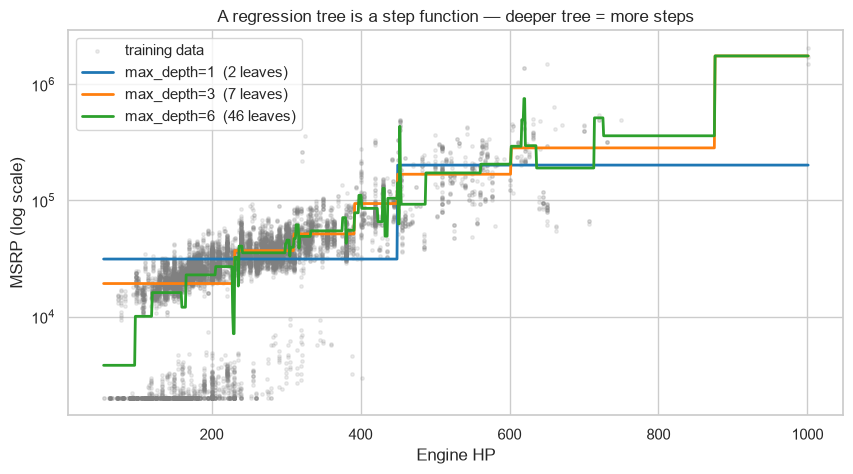

In [20]:
x_hp = X_train[['Engine HP']].to_numpy()
grid_hp = np.linspace(x_hp.min(), x_hp.max(), 1000).reshape(-1, 1)

plt.figure(figsize=(10, 5))
plt.scatter(x_hp, y_train, s=6, alpha=0.15, color="grey", label="training data")
for d, c in zip([1, 3, 6], ["tab:blue", "tab:orange", "tab:green"]):
    m = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(x_hp, y_train)
    plt.plot(grid_hp, m.predict(grid_hp), color=c, lw=2, label=f"max_depth={d}  ({m.get_n_leaves()} leaves)")
plt.yscale('log')
plt.xlabel("Engine HP"); plt.ylabel("MSRP (log scale)")
plt.title("A regression tree is a step function — deeper tree = more steps")
plt.legend(); plt.show()

## 8. Feature importance

The importance of feature $j$ is the total (weighted) **variance reduction** of all nodes that split on $j$,
normalized to sum to 1:
$$
\text{Imp}(j) = \sum_{t \,:\, \text{split on } j} \frac{N_t}{N}\,\Delta(t)
$$

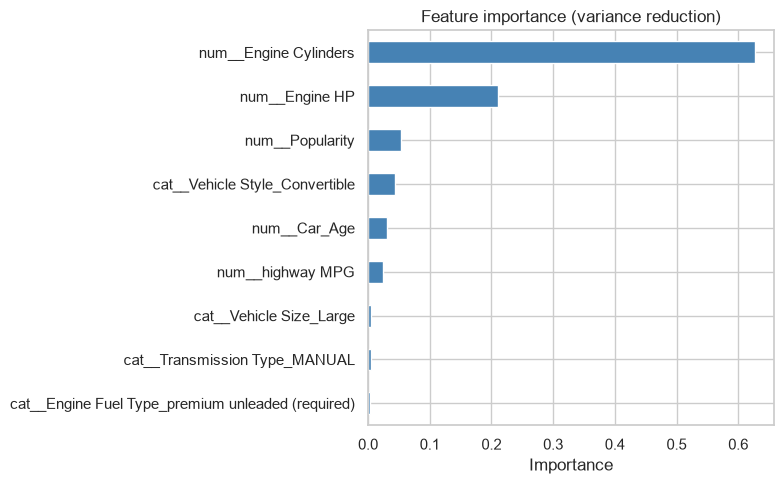

num__Engine Cylinders                                0.627
num__Engine HP                                       0.210
num__Popularity                                      0.053
cat__Vehicle Style_Convertible                       0.044
num__Car_Age                                         0.031
num__highway MPG                                     0.024
cat__Vehicle Size_Large                              0.004
cat__Transmission Type_MANUAL                        0.004
cat__Engine Fuel Type_premium unleaded (required)    0.003


In [21]:
importances = pd.Series(dt_model.feature_importances_, index=transformed_feature_names)
top = importances[importances > 0].sort_values()

plt.figure(figsize=(8, 5))
top.plot.barh(color="steelblue")
plt.title("Feature importance (variance reduction)")
plt.xlabel("Importance")
plt.tight_layout(); plt.show()
print(top.sort_values(ascending=False).round(3).to_string())

## 9. Overfitting & the bias–variance trade-off

A fully grown regression tree can put **every training car in its own leaf**, reaching training $R^2 = 1$ while
generalizing worse. Let's compare training and test $R^2$ as `max_depth` grows.

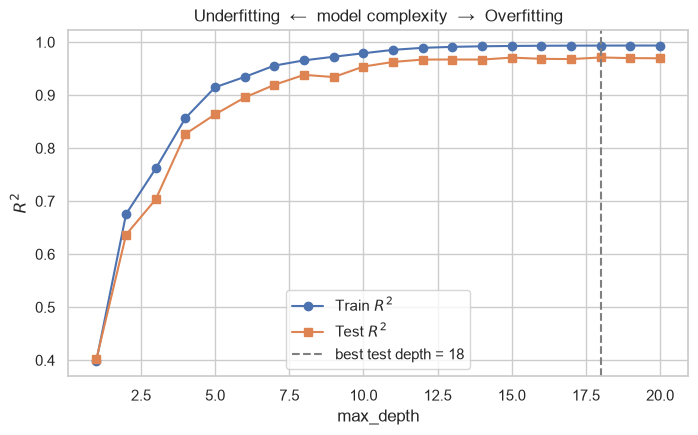

In [22]:
depths = range(1, 21)
train_r2, test_r2 = [], []
for d in depths:
    model = Pipeline([('preprocessor', preprocessor),
                      ('regressor', DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))])
    model.fit(X_train, y_train)
    train_r2.append(model.score(X_train, y_train))
    test_r2.append(model.score(X_test, y_test))

best_d = depths[int(np.argmax(test_r2))]
plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_r2, "o-", label="Train $R^2$")
plt.plot(depths, test_r2, "s-", label="Test $R^2$")
plt.axvline(best_d, color="grey", ls="--", label=f"best test depth = {best_d}")
plt.xlabel("max_depth"); plt.ylabel("$R^2$")
plt.title("Underfitting  ←  model complexity  →  Overfitting")
plt.legend(); plt.show()

## 10. Hyper-parameter tuning with cross-validation

We must not tune on the test set, so we use **k-fold cross-validation** on the training data:
$$
\text{CV score} = \frac{1}{k}\sum_{i=1}^{k}\text{score}_i
$$
`GridSearchCV` tries every combination below and keeps the one with the best average CV score
(here: lowest RMSE — scikit-learn maximizes scores, so the metric is `neg_root_mean_squared_error`).

In [23]:
param_grid = {
    'regressor__max_depth': [5, 8, 12, 16, None],
    'regressor__min_samples_leaf': [1, 3, 5, 10],
}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print(f"Best CV RMSE    : {-grid.best_score_:,.2f}")

y_pred_best = grid.predict(X_test)
print(f"\nTest RMSE (tuned): {np.sqrt(mean_squared_error(y_test, y_pred_best)):,.2f}   vs  baseline {rmse:,.2f}")
print(f"Test R2   (tuned): {r2_score(y_test, y_pred_best):.3f}   vs  baseline {r2:.3f}")

Best parameters : {'regressor__max_depth': None, 'regressor__min_samples_leaf': 1}
Best CV RMSE    : 19,007.91

Test RMSE (tuned): 8,526.55   vs  baseline 17,411.19
Test R2   (tuned): 0.967   vs  baseline 0.864


> 💬 **Discussion:** cross-validation selects a **fully grown** tree, and test $R^2$ jumps a lot. Why doesn't it overfit?
> The dataset contains many *near-duplicate* rows (the same model sold in several trims and years), so almost every test car
> has a "twin" in the training set that a deep tree can memorize. In a real deployment (predicting **new** models)
> this would be optimistic. Try a *grouped* split by `Model` (`GroupShuffleSplit`) and see what happens!

## 11. Summary

* A regression tree splits the data to maximize **variance (MSE) reduction**; each leaf predicts the **mean** of its training targets.
* The resulting model is a **piece-wise constant** (step) function.
* Evaluate with **MAE, RMSE** (in target units) and **$R^2$** (share of variance explained).
* Deep trees overfit — control complexity with `max_depth`, `min_samples_leaf`, … chosen by **cross-validation**.

### ✍️ Exercises (fork the repo and try them!)
1. Train on $\log(\text{MSRP})$ instead of MSRP (`np.log1p`) and transform predictions back with `np.expm1`. Does RMSE improve?
2. Use `criterion='absolute_error'`. Verify that a leaf now predicts the **median** of its samples.
3. Add `Make` as a categorical feature. How do feature importances change?
4. Remove the `StandardScaler` and confirm predictions are unchanged — explain why.
5. Post-prune the tree with `ccp_alpha` (see `cost_complexity_pruning_path`).
6. Compare with `RandomForestRegressor` and `GradientBoostingRegressor`.
7. Split train/test with `GroupShuffleSplit(groups=data['Model'])` so no car model appears in both sets. How do the metrics change?